# Panjer, FFT y Monte Carlo frente al valor de referencia de Shevchenko

**Pregunta:** ¿Coinciden la recursión de Panjer, la transformada rápida de Fourier y Monte Carlo con una vara de medir publicada y entre sí, y qué capital de 99,9% dan para el banco sintético?


- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema (la pérdida anual como frecuencia por severidad)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook puedes:

- discretizar una severidad en una grilla y decir qué significa la masa más allá de la grilla;
- enunciar la recursión de Panjer para una frecuencia Poisson, verificar sus primeros términos a mano y correrla con el motor;
- calcular la misma distribución con la transformada rápida de Fourier y con Monte Carlo, y decir por qué hace falta el relleno con ceros;
- reproducir los números impresos en el valor de referencia de Shevchenko (media 738,9056, cuantil de 99,9% igual a 5.849) y leer la prueba `oprisk.benchmark_reproduction` del motor;
- comparar los tres métodos sobre la distribución de pérdida verdadera versionada del banco sintético.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import aggregate
from riskvalidation.validation import oprisk as oprisk_tests

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Dos insumos. El primero es **una vara analítica**, no un archivo: el ejemplo 9.4 de Shevchenko (2010), un conteo Poisson de media 100 y una severidad lognormal con $\mu = 0$ y $\sigma = 2$. Su media, varianza y asimetría se conocen en forma cerrada, y el artículo imprime su cuantil de 99,9% calculado con los tres métodos. Toda implementación de la distribución compuesta puede medirse contra ella, y el motor lo es.

El segundo es el documento versionado del caso C17 para la variante con índice de cola 0,8:

- **Archivo que se lee:** `data/derived/C17/xi-0-8.json`, la fila `oprisk.benchmark_reproduction` de `tests` (la vara tal como la registró el cálculo del caso) y el bloque `outputs.exceedance` (la probabilidad de que la pérdida anual del banco sintético supere 14 montos, por Monte Carlo, Panjer y Fourier, con el cuantil de 99,9% de cada uno).

La celda siguiente carga el documento e imprime lo que contiene la fila de la vara.

In [2]:
# Cargar el documento de la variante y leer su fila de referencia
ROOT = Path("../../..").resolve()
variant = json.loads((ROOT / "data" / "derived" / "C17" / "xi-0-8.json").read_text(encoding="utf-8"))
fila_vara = next(row for row in variant["tests"] if row["test_id"] == "oprisk.benchmark_reproduction")
print(
    "test_id:", fila_vara["test_id"], "| luz:", fila_vara["light"], "| metric:",
    round(fila_vara["metric"], 6)
)
NAMES = {
    "mean": "media", "variance": "varianza", "skewness": "asimetría", "panjer": "panjer", "fft": "fft",
    "monte-carlo": "monte-carlo"
}
print("desviaciones:", {NAMES[k]: float("%.3g" % v) for k, v in fila_vara["extras"]["deviations"].items()})
print("umbrales:", fila_vara["policy_version"])
print("calculado por riskvalidation", variant["provenance"]["riskvalidation_version"])

test_id: oprisk.benchmark_reproduction | luz: green | metric: 0.196688
desviaciones: {'media': 1.34e-08, 'varianza': 1.4e-11, 'asimetría': 1.97e-06, 'panjer': 0.0, 'fft': 0.0, 'monte-carlo': 0.000111}
umbrales: contraste-oprisk-battery 1.0.0
calculado por riskvalidation 1.0.1


## Método

La distribución compuesta de una pérdida anual $Z = \sum_{i=1}^{N} X_i$ no tiene forma cerrada para una severidad de cola pesada. Tres métodos numéricos la calculan, y cada uno se verifica contra la vara: la recursión de Panjer y la transformada rápida de Fourier trabajan sobre una grilla de montos de pérdida $0, \Delta, 2\Delta, \dots$, y Monte Carlo simula los años.

### Paso 1: discretizar la severidad

Sobre una grilla de paso $\Delta$ la severidad se vuelve una masa de probabilidad $f_j = P(X \approx j\Delta)$. La discretización central, la de la vara, pone en $j\Delta$ la masa del intervalo centrado en él (Shevchenko, 2010):

$$f_0 = F(\Delta/2), \qquad f_j = F\big((j + \tfrac12)\Delta\big) - F\big((j - \tfrac12)\Delta\big), \quad j \ge 1$$

Las masas suman a lo más 1. Lo que falta es la probabilidad de que una sola pérdida caiga más allá del último punto de la grilla; el motor la informa y nunca la renormaliza. La celda siguiente discretiza la lognormal de la vara en 6.000 puntos de paso 1.

In [3]:
# Discretizar la severidad de referencia LN(0, 2) en 6.000 puntos de paso 1
LAM, SEV = 100.0, (0.0, 2.0)
STEP, POINTS = 1.0, 6000
f = aggregate.discretise_severity("lognormal", SEV, STEP, POINTS)
print("f_0, f_1, f_2:", f[:3])
print("suma de las masas:", round(float(f.sum()), 9), "| masa más allá de la grilla:", float(1.0 - f.sum()))

f_0, f_1, f_2: [0.36445584 0.21587212 0.09624803]
suma de las masas: 0.999993184 | masa más allá de la grilla: 6.815706953267053e-06


### Paso 2: la recursión de Panjer

Para una frecuencia de la clase $(a, b, 0)$, $p_n = (a + b/n)\,p_{n-1}$, que incluye la Poisson, las probabilidades compuestas $h_n = P(Z = n\Delta)$ cumplen (Panjer, 1981; Shevchenko, 2010, teorema 5.2):

$$h_0 = \sum_{k \ge 0} f_0^{\,k}\, p_k, \qquad h_n = \frac{1}{1 - a f_0} \sum_{j=1}^{n} \left(a + \frac{b\,j}{n}\right) f_j\, h_{n-j}$$

Para un conteo Poisson($\lambda$), $a = 0$, $b = \lambda$ y $h_0 = e^{\lambda (f_0 - 1)}$. La celda siguiente pide al motor los coeficientes y $h_0$, y compara $h_0$ con la fórmula.

In [4]:
# Los coeficientes (a, b) y h_0 del caso de Poisson, desde el motor y desde la fórmula
a, b = aggregate.panjer_coefficients("poisson", (LAM,))
h0_engine = aggregate.panjer_h0("poisson", (LAM,), float(f[0]))
print("a =", a, "| b =", b, "| f_0 =", round(float(f[0]), 8))
print("h_0 motor:", h0_engine, "| exp(lambda * (f_0 - 1)):", float(np.exp(LAM * (f[0] - 1.0))))

a = 0.0 | b = 100.0 | f_0 = 0.36445584
h_0 motor: 2.504194378663635e-28 | exp(lambda * (f_0 - 1)): 2.504194378663635e-28


La recursión parte de $h_0$ y construye cada $h_n$ con los anteriores. Con $a = 0$ los dos primeros términos son lo bastante cortos para escribirlos a mano, lo que verifica que leemos la fórmula como la lee el motor: $h_1 = \lambda f_1 h_0$ y $h_2 = \tfrac{\lambda}{2} f_1 h_1 + \lambda f_2 h_0$. La celda siguiente corre `panjer_recursion` sobre toda la grilla y compara sus tres primeras probabilidades con esos términos a mano.

In [5]:
# Correr la recursión en toda la grilla y verificar sus primeros términos contra las fórmulas a mano
h_panjer = aggregate.panjer_recursion("poisson", (LAM,), f)
h1 = LAM * f[1] * h_panjer[0]
h2 = 0.5 * LAM * f[1] * h1 + LAM * f[2] * h_panjer[0]
print("h_0, h_1, h_2 (motor):", h_panjer[:3])
print("h_1, h_2 (a mano):", h1, h2)
print("probabilidad total en la grilla:", round(float(h_panjer.sum()), 9))

h_0, h_1, h_2 (motor): [2.50419438e-28 5.40585741e-27 6.07589320e-26]
h_1, h_2 (a mano): 5.40585741249232e-27 6.07589319905883e-26
probabilidad total en la grilla: 0.999063786


### Paso 3: la transformada rápida de Fourier

La misma distribución sale de las transformadas. La función generadora de probabilidad de la frecuencia, $\psi(s) = E[s^N]$, aplicada a la transformada discreta de Fourier $\hat f$ de las masas de la severidad, da la transformada del agregado; invertirla devuelve $h$ (Shevchenko, 2010, sección 6.2). Para un conteo Poisson $\psi(s) = e^{\lambda (s - 1)}$, de modo que

$$\hat h_k = \exp\big(\lambda\,(\hat f_k - 1)\big)$$

La transformada trata la grilla como periódica, así que la masa que debería quedar más allá de la grilla se pliega hacia el inicio (aliasing). Rellenar la severidad con ceros antes de transformar lo evita; el motor redondea el largo a una potencia de dos. La celda siguiente calcula $h$ con factores de relleno 1, 2 y 4 e imprime la mayor diferencia con las probabilidades de Panjer.

In [6]:
# La ruta de Fourier con tres factores de relleno, frente a las probabilidades de Panjer
alias_error = {}
for padding in (1, 2, 4):
    h_pad = aggregate.fft_aggregate("poisson", (LAM,), f, padding_factor=padding)
    alias_error[padding] = float(np.abs(h_pad - h_panjer).max())
    print("factor de relleno", padding, "| mayor diferencia con Panjer:", alias_error[padding])
h_fft = aggregate.fft_aggregate("poisson", (LAM,), f, padding_factor=2)

factor de relleno 1 | mayor diferencia con Panjer: 5.097631120125096e-09
factor de relleno 2 | mayor diferencia con Panjer: 3.8905768255485554e-14
factor de relleno 4 | mayor diferencia con Panjer: 1.235990476633475e-17


La siguiente celda dibuja el error de aliasing. A la izquierda, la mayor diferencia con Panjer para cada factor de relleno; a la derecha, cómo se reparte esa diferencia a lo largo de la grilla para el factor 1, donde el efecto de envoltura es peor.

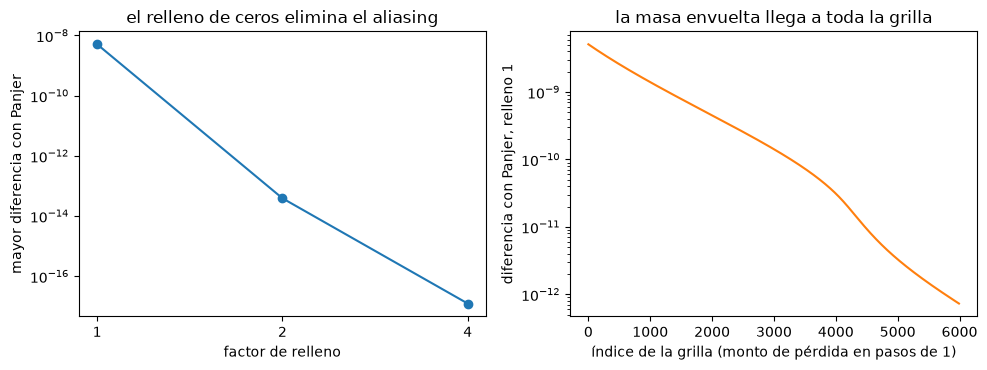

In [7]:
# Dibujar el error de aliasing de la ruta de Fourier según el factor de relleno y a lo largo de la grilla
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.semilogy([str(k) for k in alias_error], list(alias_error.values()), "o-", color="tab:blue")
left.set_xlabel("factor de relleno")
left.set_ylabel("mayor diferencia con Panjer")
left.set_title("el relleno de ceros elimina el aliasing")
h_one = aggregate.fft_aggregate("poisson", (LAM,), f, padding_factor=1)
right.semilogy(np.arange(POINTS)[::10], np.abs(h_one - h_panjer)[::10] + 1e-30, color="tab:orange")
right.set_xlabel("índice de la grilla (monto de pérdida en pasos de 1)")
right.set_ylabel("diferencia con Panjer, relleno 1")
right.set_title("la masa envuelta llega a toda la grilla")
fig.tight_layout()
plt.show()

El panel izquierdo cae unos nueve órdenes de magnitud del relleno 1 al relleno 4: 5,1e-9, 3,9e-14 y 1,2e-17. Incluso la transformada sin relleno es exacta a nueve decimales aquí, porque la masa más allá de la grilla es solo 6,8e-6, de modo que el relleno es una salvaguarda que importa cuando la cola es más pesada. El panel derecho muestra que el error sin relleno no se limita al final de la grilla: la masa envuelta se reparte en todos los índices. La figura cubre una severidad; una cola más pesada exigiría una grilla más larga antes de que el relleno ayude.

### Paso 4: el cuantil de 99,9% de la pmf, y la fe de erratas

Desde las probabilidades, el cuantil es el menor monto de la grilla cuya probabilidad acumulada alcanza el nivel: `quantile_from_pmf`. El artículo de la vara imprime las probabilidades acumuladas junto a sus índices en su tabla 2, y una transcripción temprana de esa tabla en la investigación detrás de este caso asoció el valor 0,998999329 al índice 5.849. La documentación del motor lo corrige y las sumas acumuladas lo confirman: el valor pertenece al índice 5.847, mientras que el índice 5.849 tiene 0,999000217, el primero igual o mayor que 0,999. La celda siguiente imprime la probabilidad acumulada en los tres índices y el cuantil de ambos métodos.

In [8]:
# La probabilidad acumulada cerca del nivel 99,9% y el cuantil de las pmf de Panjer y de Fourier
cumulative = np.cumsum(h_panjer)
for index in (5847, 5848, 5849):
    print("H_%d = %.9f" % (index, cumulative[index]))
q_panjer = aggregate.quantile_from_pmf(h_panjer, STEP, 0.999)
q_fft = aggregate.quantile_from_pmf(h_fft, STEP, 0.999)
print("cuantil de 99.9%: Panjer =", q_panjer, "| Fourier =", q_fft)

H_5847 = 0.998999329
H_5848 = 0.998999773
H_5849 = 0.999000217
cuantil de 99.9%: Panjer = 5849.0 | Fourier = 5849.0


### Paso 5: Monte Carlo

Monte Carlo sortea los años en vez de calcular la distribución. Una muestra de $K$ años estima el cuantil **continuo** de $Z$, mientras que los métodos de grilla devuelven el cuantil de la variable discretizada, de modo que ambos difieren en una fracción del paso; la tabla 3 de Shevchenko da 5.853,06 para el cuantil continuo con un paso fino. El cálculo del caso simula 1.000.000 de años con la semilla 2010; la celda siguiente hace lo mismo con el motor (unos cuatro segundos) e imprime el cuantil y su error estándar.

In [9]:
# Simular 1.000.000 de años de la referencia con la semilla del bake del caso y leer el cuantil
sample = aggregate.simulate_annual_losses("poisson", (LAM,), "lognormal", SEV, 1_000_000, 2010, chunk_years=50_000)
q_mc, se_mc = aggregate.mc_quantile(sample.losses, 0.999)
print("años simulados:", sample.n_years, "| cuantil de 99.9%:", round(q_mc, 2), "| error estándar:", round(se_mc, 1))

años simulados: 1000000 | cuantil de 99.9%: 5853.75 | error estándar: 68.1


La siguiente celda dibuja la distribución de la vara de medir como la ven los tres métodos: la probabilidad de que la pérdida anual supere un monto, por Panjer y por Fourier como líneas y por los años simulados como puntos, con el cuantil de 99,9% marcado.

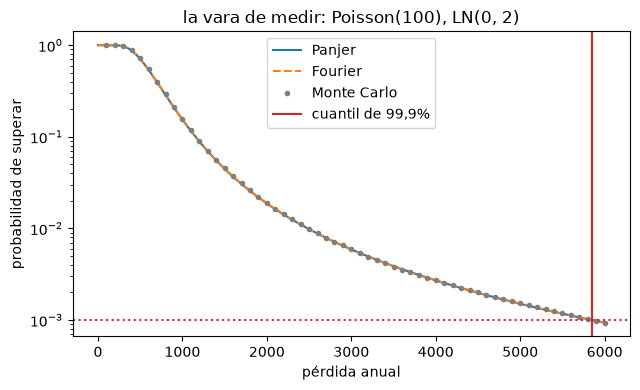

In [10]:
# Dibujar la excedencia de la vara de medir por Panjer, Fourier y Monte Carlo, con el cuantil de 99,9% marcado
fig, ax = plt.subplots(figsize=(6.5, 4.0))
x_pmf, sf_panjer = aggregate.exceedance_from_pmf(h_panjer, STEP)
_, sf_fft = aggregate.exceedance_from_pmf(h_fft, STEP)
ax.semilogy(x_pmf[:6000:20], sf_panjer[:6000:20], color="tab:blue", label="Panjer")
ax.semilogy(x_pmf[:6000:20], sf_fft[:6000:20], "--", color="tab:orange", label="Fourier")
mc_sorted = np.sort(sample.losses)
mc_x = np.linspace(100, 6000, 60)
mc_sf = 1.0 - np.searchsorted(mc_sorted, mc_x, side="right") / mc_sorted.size
ax.semilogy(mc_x, mc_sf, ".", color="tab:gray", label="Monte Carlo")
ax.axvline(q_panjer, color="tab:red", label="cuantil de 99,9%")
ax.axhline(0.001, color="tab:red", linestyle=":")
ax.set_xlabel("pérdida anual")
ax.set_ylabel("probabilidad de superar")
ax.set_title("la vara de medir: Poisson(100), LN(0, 2)")
ax.legend()
fig.tight_layout()
plt.show()

Las curvas de Panjer y de Fourier quedan una sobre otra, lo que predice una diferencia de 3,9e-14, y los puntos simulados las siguen hasta la línea punteada en probabilidad 0,001. La vertical roja es el cuantil de la grilla 5849,0, mientras la simulación de 1.000.000 de años da 5853,75 con un error estándar de 68,1: a cerca de un error estándar del cuantil continuo que reporta el artículo, como se espera de una estimación que descansa en 1.000 años simulados sobre el nivel. La figura muestra acuerdo en escala logarítmica, que oculta diferencias menores que unos pocos por ciento.

### Paso 6: los momentos

La suma Poisson compuesta tiene momentos en forma cerrada: $E[Z] = \lambda E[X]$, $\mathrm{Var}[Z] = \lambda E[X^2]$ y asimetría $\lambda E[X^3] / \mathrm{Var}[Z]^{3/2}$ (Shevchenko, 2010, ejemplo 9.4). `compound_poisson_moments` los devuelve. La media de la pmf **discretizada** es menor por la masa más allá de la grilla; el motor nunca renormaliza, y su pérdida esperada en la cola (expected shortfall) rechaza una grilla que no cubre la cola. La celda siguiente imprime los momentos en forma cerrada frente a los del artículo, la media de la pmf, y la masa más allá de la grilla junto al máximo que acepta la pérdida esperada en la cola del motor, una milésima de la probabilidad de cola $1 - 0,999$, es decir $10^{-6}$.

In [11]:
# Momentos de forma cerrada contra los publicados, y la masa más allá de la grilla
moments = aggregate.compound_poisson_moments(LAM, "lognormal", SEV)
published = (738.9056, 298095.7987, 40.3428)
engine_values = (moments.mean, moments.variance, moments.skewness)
for name, value, ref in zip(("media", "varianza", "asimetría"), engine_values, published):
    print("%-12s motor %.4f | publicado %.4f | diferencia relativa %.2e" % (name, value, ref, abs(value - ref) / ref))
grid = np.arange(POINTS) * STEP
print("media de la pmf en la grilla:", round(float((grid * h_panjer).sum()), 4))
missing = 1.0 - float(h_panjer.sum())
allowed = round(1e-3 * (1.0 - 0.999), 12)
print(
    "masa más allá de la grilla:", round(missing, 6),
    "| máximo que acepta la pérdida esperada en la cola (1e-3 de la probabilidad de cola):", allowed
)
try:
    aggregate.es_from_pmf(h_panjer, STEP, 0.999)
except ValueError:
    print("el motor rechaza la pérdida esperada en la cola en esta grilla: no cubre la cola")

media        motor 738.9056 | publicado 738.9056 | diferencia relativa 1.34e-08
varianza     motor 298095.7987 | publicado 298095.7987 | diferencia relativa 1.40e-11
asimetría    motor 40.3429 | publicado 40.3428 | diferencia relativa 1.97e-06
media de la pmf en la grilla: 725.7655
masa más allá de la grilla: 0.000936 | máximo que acepta la pérdida esperada en la cola (1e-3 de la probabilidad de cola): 1e-06
el motor rechaza la pérdida esperada en la cola en esta grilla: no cubre la cola


### Paso 7: la prueba de reproducción del motor

`oprisk.benchmark_reproduction` recibe los tres momentos y los tres cuantiles y devuelve un `TestResult`. La desviación de un momento es su diferencia relativa con el valor del artículo. Un cuantil de Panjer o de Fourier desvía cero dentro del rango impreso 5.849 a 5.850, y el de Monte Carlo se compara con el continuo 5.853,1. La métrica es la mayor desviación dividida por su tolerancia (`moment_rel_tol` 1e-5, `quantile_rel_tol` 0,01); es verde si la métrica es a lo más 1, ámbar hasta 2 y roja sobre eso. Son **umbrales internos del caso**, descriptivos y sin valor p. La tolerancia sobre los momentos debe superar el redondeo de la asimetría impresa, 40,3428 frente al exacto $e^6/10 = 40,342879$. La celda siguiente corre la prueba con nuestros números y la pone junto a la fila versionada.

In [12]:
# Correr la prueba de reproducción sobre nuestros números y compararla con la fila versionada
test = oprisk_tests.benchmark_reproduction(
    (moments.mean, moments.variance, moments.skewness), {"monte-carlo": q_mc, "panjer": q_panjer, "fft": q_fft},
    moment_rel_tol=1e-5
)
print("%-26s %14s %14s" % ("", "recalculado", "versionado"))
print("%-26s %14.6f %14.6f" % ("metric", test.metric, fila_vara["metric"]))
print("%-26s %14s %14s" % ("luz", test.light.value, fila_vara["light"]))
for name, value in test.extras["deviations"].items():
    print("%-26s %14.3e %14.3e" % ("desviación " + NAMES[name], value, fila_vara["extras"]["deviations"][name]))
print(
    "calculado por riskvalidation", variant["provenance"]["riskvalidation_version"], "| instalado",
    md.version("riskvalidation")
)

                              recalculado     versionado
metric                           0.196688       0.196688
luz                                 green          green
desviación media                1.339e-08      1.339e-08
desviación varianza             1.400e-11      1.400e-11
desviación asimetría            1.967e-06      1.967e-06
desviación panjer               0.000e+00      0.000e+00
desviación fft                  0.000e+00      0.000e+00
desviación monte-carlo          1.114e-04      1.114e-04
calculado por riskvalidation 1.0.1 | instalado 1.0.1


### Paso 8: los mismos tres métodos sobre la distribución de pérdida verdadera del banco

Para el banco sintético el caso versionó la probabilidad de que la pérdida anual supere 14 montos, por cada método, y el cuantil de 99,9%. El bloque de Panjer declara su paso, y la severidad y la frecuencia son los parámetros verdaderos de la variante, así que el motor puede recalcularlo. La celda siguiente lo hace con 32.768 puntos de grilla (unos cinco segundos), lee la curva de excedencia con `exceedance_from_pmf` en los 14 montos y la compara con el bloque de Panjer versionado; luego imprime el cuantil de 99,9% de los cuatro métodos versionados, el cuarto siendo la aproximación de pérdida única del notebook 04. Más allá del fin de la grilla de la recursión el bloque de Panjer versionado es nulo, porque la recursión no tiene masa que dar ahí; esos montos quedan fuera de la comparación.

In [13]:
# Recalcular la excedencia de Panjer de la pérdida anual verdadera y compararla con los bloques versionados
truth = variant["outputs"]["truth"]
exceedance = variant["outputs"]["exceedance"]
lam_bank = truth["frequency"]["lambda_per_year"]
sev_bank = (truth["severity"]["tail_index"], truth["severity"]["scale_eur"], truth["severity"]["location_eur"])
step_bank = exceedance["panjer"]["step_eur"]
f_bank = aggregate.discretise_severity("gpd", sev_bank, step_bank, 32768)
h_bank = aggregate.panjer_recursion("poisson", (lam_bank,), f_bank)
nodes, sf_nodes = aggregate.exceedance_from_pmf(h_bank, step_bank)
amounts = np.array(exceedance["grid_eur"])
sf_recomputed = np.interp(amounts, nodes, sf_nodes)
# más allá del fin de la grilla de la recursión el bloque de Panjer versionado es nulo (c17-outputs 2.0.0): esos
# montos no se comparan
versionado_panjer = np.array([np.nan if v is None else v for v in exceedance["panjer"]["exceedance"]], dtype=float)
covered = ~np.isnan(versionado_panjer)
versionado_fft = np.array(exceedance["fft"]["exceedance"])
versionado_mc = np.array(exceedance["monte_carlo"]["exceedance"])
print("masa más allá de la grilla:", round(1.0 - float(h_bank.sum()), 6), "| paso (EUR):", step_bank)
print(
    "la grilla de Panjer termina en EUR", format(step_bank * (len(f_bank) - 1), ",.0f"),
    "| montos más allá, nulos en el documento:", int((~covered).sum())
)
print(
    "mayor diferencia con el bloque de Panjer versionado:",
    float(np.abs(sf_recomputed[covered] - versionado_panjer[covered]).max())
)
print(
    "mayor diferencia Panjer - Fourier, versionado:",
    float(np.abs(versionado_panjer[covered] - versionado_fft[covered]).max())
)
print("mayor diferencia Monte Carlo - Fourier, versionado:", float(np.abs(versionado_mc - versionado_fft).max()))
for method, value in exceedance["quantile_999_eur"].items():
    print("cuantil de 99.9%% %-12s EUR %s" % (method, format(value, ",.0f")))

masa más allá de la grilla: 0.00075 | paso (EUR): 6236.38153
la grilla de Panjer termina en EUR 204,347,514 | montos más allá, nulos en el documento: 3
mayor diferencia con el bloque de Panjer versionado: 5.150869730741192e-10
mayor diferencia Panjer - Fourier, versionado: 0.0006024859999999022
mayor diferencia Monte Carlo - Fourier, versionado: 0.00019182299999997987
cuantil de 99.9% monte_carlo  EUR 162,770,645
cuantil de 99.9% panjer       EUR 163,486,742
cuantil de 99.9% fft          EUR 163,483,000
cuantil de 99.9% sla          EUR 157,682,341


La siguiente celda dibuja la pérdida anual verdadera del banco por los tres métodos versionados. A la izquierda, la probabilidad de superar cada uno de los 14 montos del documento; a la derecha, la brecha con signo de Panjer y de Monte Carlo respecto de la curva de Fourier, que el panel izquierdo no puede mostrar.

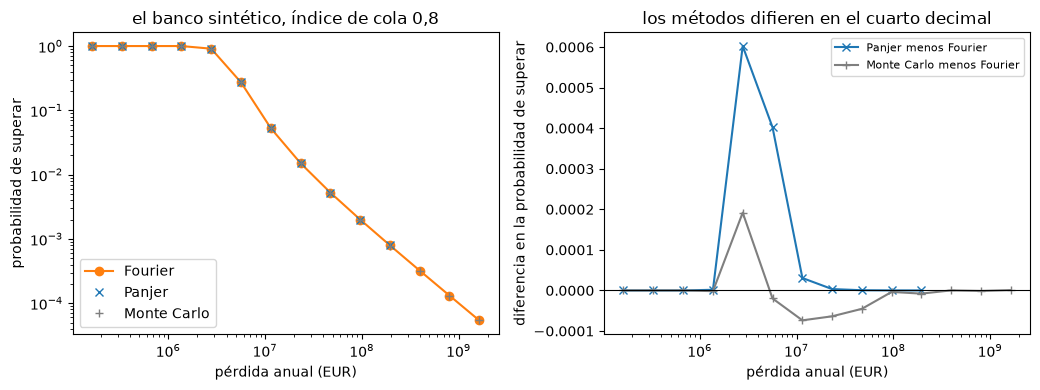

In [14]:
# Dibujar la excedencia del banco por los tres métodos versionados y la brecha de dos de ellos respecto de la curva
# de Fourier
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.0))
left.loglog(amounts, versionado_fft, "o-", color="tab:orange", label="Fourier")
left.loglog(amounts, versionado_panjer, "x", color="tab:blue", label="Panjer")
left.loglog(amounts, versionado_mc, "+", color="tab:gray", label="Monte Carlo")
left.set_xlabel("pérdida anual (EUR)")
left.set_ylabel("probabilidad de superar")
left.set_title("el banco sintético, índice de cola 0,8")
left.legend(loc="lower left")
right.semilogx(amounts, versionado_panjer - versionado_fft, "x-", color="tab:blue", label="Panjer menos Fourier")
right.semilogx(amounts, versionado_mc - versionado_fft, "+-", color="tab:gray", label="Monte Carlo menos Fourier")
right.axhline(0.0, color="black", linewidth=0.8)
right.set_xlabel("pérdida anual (EUR)")
right.set_ylabel("diferencia en la probabilidad de superar")
right.set_title("los métodos difieren en el cuarto decimal")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

A la izquierda los tres métodos son una curva a simple vista. A la derecha se ven las brechas: Panjer menos Fourier llega a 6,0e-4 y Monte Carlo menos Fourier a 1,9e-4 en probabilidad, unas pocas décimas de por ciento de las mayores probabilidades y muy bajo cualquier uso regulatorio, porque la grilla de Panjer tiene un paso de EUR 6.236 y la de Fourier un paso de EUR 1.000. Los cuantiles de 99,9% coinciden más que las curvas (EUR 163.486.742 frente a EUR 163.483.000). La figura usa los arreglos versionados, así que no prueba el motor; el recálculo de arriba sí.

## Resultados

**Respuesta:** Sí. En la vara de Shevchenko el cuantil de 99,9% es 5849,0 por Panjer y por Fourier, igual al 5.849 publicado, y 5853,75 (error estándar 68,1) por Monte Carlo; la `oprisk.benchmark_reproduction` recalculada tiene métrica 0,196688 y es verde. En el banco sintético el capital es EUR 163.486.742 por Panjer, EUR 163.483.000 por Fourier y EUR 162.770.645 por Monte Carlo, mientras la aproximación de pérdida única da EUR 157.682.341.

- **Discretización.** Con 6.000 puntos de paso 1 las masas centrales suman 0,999993; la masa más allá de la grilla es 6,8e-6, y se informa, no se renormaliza.
- **Panjer.** El $h_0$ del motor es igual a $e^{\lambda (f_0 - 1)}$ hasta el último dígito (2,5e-28), y su $h_1$ y su $h_2$ son iguales a las fórmulas a mano en todos los dígitos impresos. Para la suma compuesta de 100 pérdidas esperadas la grilla cubre 0,999064 de la probabilidad, así que 0,000936 queda más allá.
- **Fourier.** La mayor diferencia con Panjer es 5,1e-9 con factor de relleno 1, 3,9e-14 con factor 2 y 1,2e-17 con factor 4: más relleno con ceros, menos aliasing, y con factor 2 los dos métodos coinciden en 14 decimales.
- **El cuantil y la fe de erratas.** La probabilidad acumulada es 0,998999329 en el índice 5.847 y 0,999000217 en el índice 5.849, así que el cuantil de 99,9% es 5.849 por Panjer y por Fourier, dentro del rango impreso 5.849 a 5.850. El valor 0,998999329 pertenece al índice 5.847.
- **Monte Carlo.** 1.000.000 de años con la semilla 2010 dan 5.853,75 con un error estándar de 68, que estima el cuantil continuo (5.853,1 en el artículo); los métodos de grilla dan el cuantil de la variable discretizada.
- **Momentos.** La media, varianza y asimetría en forma cerrada difieren de los valores publicados en 1,3e-8, 1,4e-11 y 2,0e-6, la última siendo el redondeo del 40,3428 impreso. La media de la pmf en la grilla es 725,77 frente a 738,91, el costo de la masa faltante, y el motor rechaza ahí una pérdida esperada en la cola porque 0,000936 supera el 1e-6 que acepta.
- **La prueba.** La `oprisk.benchmark_reproduction` recalculada tiene métrica 0,196688 y es verde, idéntica a la fila versionada en todos los dígitos impresos, incluida la desviación de Monte Carlo 1,114e-4: la misma semilla da la misma muestra, así que la simulación es reproducible.
- **El banco.** La excedencia de Panjer recalculada desde el paso versionado y los parámetros verdaderos coincide con el bloque versionado hasta 5,2e-10. Panjer y Fourier difieren hasta 6,0e-4 en probabilidad entre los bloques versionados porque sus grillas difieren (pasos de EUR 6.236 y EUR 1.000), pero sus cuantiles de 99,9% difieren en 0,002%, EUR 163,487 millones frente a EUR 163,483 millones. El cuantil Monte Carlo versionado de 10.000.000 de años es EUR 162,771 millones, 0,44% más abajo, a menos de un error estándar; la aproximación de pérdida única, EUR 157,682 millones, queda 3,6% más abajo (notebook 04).

Lo que este notebook no muestra: los ajustes que dan a la severidad sus parámetros (notebook 02), la aproximación de forma cerrada (notebook 04) o por qué el mismo capital es estable o no entre historias (notebook 06 y el notebook de nivel 4).

## Resumen

- La distribución compuesta de una pérdida anual se calcula en una grilla con la recursión de Panjer o con la transformada rápida de Fourier, y por simulación; el motor reproduce la vara publicada con los tres.
- Panjer y Fourier coinciden a precisión de máquina sobre la misma grilla; el relleno con ceros controla el aliasing; la masa más allá de la grilla se informa y nunca se renormaliza.
- Monte Carlo estima el cuantil continuo con un error estándar que cae despacio; los métodos de grilla devuelven el cuantil de la variable discretizada.
- La prueba de reproducción es un umbral interno sin valor p, y el motor instalado reproduce exactamente la fila versionada.

**Qué probar a continuación.** Cambia `STEP` a 0,5 y `POINTS` a 12000 y mira cómo se mueven el cuantil y la masa más allá de la grilla. Reemplaza la lognormal por la Pareto generalizada del banco y mira cómo la grilla no alcanza a cubrir la cola salvo que crezca su extensión. Sigue con el notebook 04.

## Referencias

- Panjer, H. H. (1981), Recursive evaluation of a family of compound distributions, ASTIN Bulletin 12(1), 22-26. https://doi.org/10.1017/S0515036100006796
- Shevchenko, P. V. (2010), Calculation of aggregate loss distributions, Journal of Operational Risk 5(2), 3-40. https://arxiv.org/abs/1008.1108 y https://doi.org/10.21314/JOP.2010.077